# Machine Learning
### Practice 6
### Myrzakassymov Azizkhan

This notebook is about dataset, model and metrics.

### Dataset
GTA VI user-reviews. 

reviews.csv is a UTF-8 CSV with 15,657 rows and five columns. 

Each row represents the first captured review for a given Metacritic profile and platform. 

The combination of platform and review_id uniquely identifies a row.

#### Task

Imagine if Sam Houser from Rockstar Games has an email in which fans can write to him freely,

our model is going to sort out bad reviews to him not feel bad, because this hate is very forced, but leave him at least real critique.

In [1]:
import pandas as pd
import numpy as np

In [2]:
dataset = pd.read_csv('reviews.csv')

dataset

,platform,review_id,published_date,score,review_text
0,playstation-5,mc-profile-73221238ba69e82808a52ea6f11af92abf3...,2026-11-21,6,"I guess it’s just more GTA.\nNo innovations, n..."
1,playstation-5,mc-profile-24d933ed22bfa70a548d54edf921231c088...,2026-11-21,0,"Me decepciono, tanto tiempo que esperamos para..."
2,playstation-5,mc-profile-b4599596d3980783f5b65eee7914d9daa11...,2026-11-21,0,13 years to be capped at 30 fps in 2026. Horri...
3,playstation-5,mc-profile-0ffa47434c1d38d82f989d3adde82423fe0...,2026-11-21,0,I'm so disappointed in this woke feminist garb...
4,playstation-5,mc-profile-cdf748f019c011aac056781d7abb47f6a34...,2026-11-21,9,I’m currently on chapter 3 and I’m enjoying th...
...,...,...,...,...,...
43255,xbox-series-x,mc-profile-88e398ea5b974dccd3b32d816536f56d760...,2026-11-22,0,"Переоценное, не оптимизированное говно с душны..."
43256,xbox-series-x,mc-profile-cb826e9d8d4e407c10e6b534101084ef333...,2026-11-22,10,Lucia got a big ass gyaaaat dayuuuum. Imponte ...
43257,xbox-series-x,mc-profile-5b0a01fcd109fdeb4f9e16eed0fd6f9df81...,2026-11-22,5,é impressionante terem passado 13 anos usando ...
43258,xbox-series-x,mc-profile-f031715555d82eb9e5c1f58e76ba40e37e8...,2026-11-21,1,Girl Theft Auto. Das Spiel hat leider überhaup...


Quick EDA to see distributions of score that will be our target, word frequencies etc.

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Aggregation of target variable

agg = dataset.groupby('published_date').agg(
    {'score' : ['mean', 'std']}, 
)

agg

score          
                    mean       std
published_date                    
2026-11-19      1.333333  2.309401
2026-11-20      4.744229  4.287975
2026-11-21      5.039527  4.376210
2026-11-22      5.025309  4.381042

To make it more interpretable let's make barplots

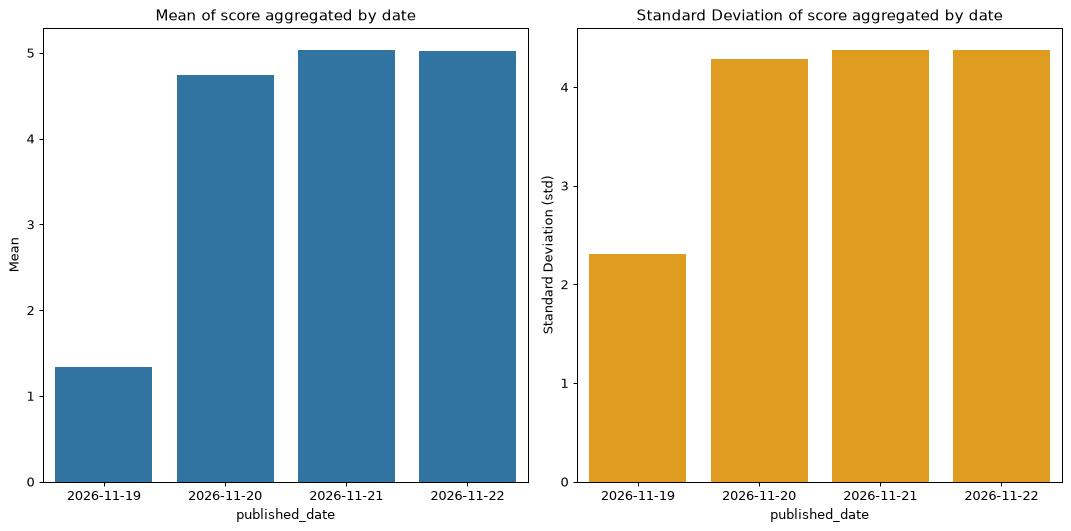

In [5]:
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(12, 6), dpi=90)

sns.barplot(
    data=agg[('score','mean')],
    ax=ax[0]
)
ax[0].set_title('Mean of score aggregated by date')
ax[0].set_ylabel('Mean')

sns.barplot(
    data=agg[('score', 'std')],
    ax=ax[1],
    color='orange'
)
ax[1].set_title('Standard Deviation of score aggregated by date')
ax[1].set_ylabel('Standard Deviation (std)')

plt.tight_layout()
plt.show()

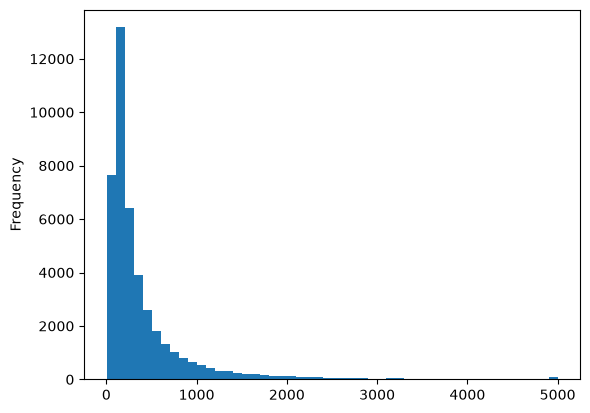

In [ ]:
dataset['review_text'].str.len().plot.hist(bins=50)
plt.show()

In [ ]:
dataset['review_text'].str.len().max()

np.int64(5000)

### Building the model 

In [2]:
from sklearn.base import BaseEstimator, TransformerMixin
import re

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, punctuations=r"""@#!?+&*[]-%.:/();$=><|{}^'`"""):
        self.punctuations = punctuations

    def fit(self, X, y=None):
        return self

    def _to_1d_strings(self, X):
        if isinstance(X, pd.DataFrame):
            series = X.iloc[:, 0]
        elif isinstance(X, pd.Series):
            series = X
        else:
            series = pd.Series(np.asarray(X).ravel())
        return series.fillna("").astype(str).tolist()

    def transform(self, X):
        texts = self._to_1d_strings(X)
        trans_table = str.maketrans("", "", self.punctuations)

        converted = []
        for text in texts:
            text = text.lower()
            text = re.sub(r"[^a-zA-Z?.!,¿0-9/']", " ", text) # replace everything with space except (a-z, 0-9, A-Z, ".", "?", "!", ",")
            text = re.sub(r"[\n\r\t]", " ", text)
            text = re.sub(r"[’`]", "'", text)
            text = text.translate(trans_table)
            converted.append(text)
        return converted

everything that is written here is going to be saved in train.py

In [ ]:
import langid

eng_text = dataset['review_text'].fillna("").astype(str).apply(lambda x: langid.classify(x)[0])
print(eng_text[:10])

In [ ]:
dataset_eng = dataset[eng_text=="en"] # to make dataset_eng

In [ ]:
dataset_eng.to_csv('reviews_en.csv') # to save dataset

In [4]:
dataset_eng = pd.read_csv('reviews_en.csv')

X, y = dataset_eng[['review_text']], dataset_eng['score']

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
features = FeatureUnion(
    transformer_list=[
        ('tfidfwords', TfidfVectorizer(max_features=70000, ngram_range=(1, 3), dtype=np.float32, sublinear_tf=True)),
        ('tfidfchars', TfidfVectorizer(max_features=30000, ngram_range=(3, 5), dtype=np.float32, sublinear_tf=True, analyzer='char_wb'))
    ]
)

pipeline = Pipeline(
    steps=[
        ('cleaning', TextCleaner()),
        ('features', features),
        ('regression', LogisticRegression(C=5, max_iter=3000))
    ]
)


pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaning', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](11,)","[ 0, 1, 2,..., 8, 9,10]"
,punctuations,"""@#!?+&*[]-%.:/();$=><|{}^'`"""
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('tfidfwords', ...), ('tfidfchars', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False


In [16]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error, accuracy_score

y_proba = pipeline.predict_proba(X_test)
y_pred = np.rint(y_proba @ pipeline.classes_)

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("RMSE: ", root_mean_squared_error(y_test, y_pred))
print("R**2: ", r2_score(y_test, y_pred))

Accuracy:  0.37350657108721624
MAE:  1.3294504181600957
RMSE:  2.107051369075642
R**2:  0.7636640297175789


In [23]:
reviews = ["Hey Sam, I think this game is okay, but don't get me wrong, there's plenty of things must be done right you know, but I still enjoyed",
           "WOOOW BEST GAME OF ALL TIME THANKS SAM AND ALL OF YOUR TEAM YOU ARE THE BEST",
           "Man we waited for long time, my man I GAVE YOU 120 DOLLARS FOR THIS AND YOU AWAIT FOR ME TO DO DISHES?",
           "Game is fine, but I wouldn't add chores in GTA game, but graphics is very good! like photorealistic!",
           "Don't listen to all the chuds are saying that this is a goyslop. Best game of all time"]

y_proba = pipeline.predict_proba(reviews)
y_pred = np.rint(y_proba @ pipeline.classes_)

print(y_pred)

[ 7. 10.  1.  5.  9.]
